# Z24: selección del modelo, versión 2

Rehace la selección del modelo de `z24_early_damage_detection.ipynb` con un proceso ordenado: primero se fijan la métrica y la validación, después se construyen todas las variables, se compara una escalera de modelos con sus hiperparámetros propios y se elige el modelo con una regla escrita de antemano. Los bloques de prueba se miran una sola vez, al final (sección 10).

Se usan los mismos datos, bloques, folds, limpieza y sistema de detección del notebook actual.

**Índice**
1. [Problema, métrica y validación](#sec1)
2. [Limpieza de datos](#sec2)
3. [Exploración](#sec3)
4. [Variables](#sec4)
5. [Referencia trivial](#sec5)
6. [Escalera de modelos](#sec6)
7. [Ajuste de hiperparámetros](#sec7)
8. [Comparación de modelos](#sec8)
9. [Selección del modelo](#sec9)
10. [Sistema de detección con el modelo elegido](#sec10)
11. [Información adicional](#sec11)
12. [Conclusiones y limitaciones](#sec12)

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Fixed seed, so that any random result is always the same
SEED = 42
np.random.seed(SEED)

# Input files (in the parent folder, bridge-z24) and folder for the tuning results
FREQUENCIES_FILE = "../results/ems_natural_frequencies.csv"
ENVIRONMENT_FILE = "../cache/ems_inventory.csv"
TUNING_FOLDER = "tuning_v2"
os.makedirs(TUNING_FOLDER, exist_ok=True)

# Important dates
TEST_START = pd.Timestamp("1998-07-15")           # start of the healthy test block
PREP_START = pd.Timestamp("1998-08-05")           # start of the damage preparation
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering

MODES = [1, 2, 3]
PANEL_LABELS = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)", "(h)"]


# Shows a table with its caption above it
def show_table(table, number, caption, decimals=3):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    display(table.style.hide(axis="index").format(precision=decimals))


# Shows a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Problema, métrica y validación

**Problema.** La temperatura cambia las frecuencias del Z24 tanto como el daño. Se entrena, solo con el puente sano, un modelo que predice la frecuencia de cada modo a partir de la temperatura; el daño se busca en el residuo:

$$
r_{m,i} = f_{m,i} - \hat{f}_m(\mathbf{x}_i)
\tag{1}
$$

donde $f_{m,i}$ es la frecuencia medida del modo $m$ en la medición $i$, $\mathbf{x}_i$ sus variables de entrada y $\hat{f}_m$ la predicción del modelo.

**Métrica** (fijada antes de modelar): RMSE de la validación cruzada por semanas, por modo, en total, bajo 0 °C y sobre 0 °C:

$$
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} r_i^2}
\tag{2}
$$

donde $r_i$ es el residuo fuera del fold de la medición $i$ y $n$ el número de mediciones.

**Validación.** Los mismos folds del notebook actual: cada medición del entrenamiento recibe su semana, contada desde la primera medición, y las semanas se reparten por turnos en $k = 5$ folds (semana 0 → fold 1, semana 1 → fold 2, ..., semana 5 → fold 1). Cada fold se predice con un modelo entrenado con los otros cuatro.

**Bloques de prueba** (puente sano, 15.07 al 04.08.1998; con daño, desde el 11.08.1998, 13:15): no se usan para ninguna decisión hasta la sección 10.

In [2]:
# 1. Frequencies and pavement temperature (same steps as the current notebook)
frequencies = pd.read_csv(FREQUENCIES_FILE, parse_dates=["start"])
temperatures = pd.read_csv(ENVIRONMENT_FILE, usecols=["code", "TP1", "TP2"])

# Error codes of the data logger (for example 3276.7) are replaced by NaN
temperatures.loc[temperatures["TP1"].abs() >= 100, "TP1"] = np.nan
temperatures.loc[temperatures["TP2"].abs() >= 100, "TP2"] = np.nan
temperatures["T"] = temperatures[["TP1", "TP2"]].mean(axis=1)      # pavement temperature

data = pd.merge(frequencies, temperatures[["code", "T"]], on="code", how="left")
data = data.sort_values("start").reset_index(drop=True)


# 2. Time block of each measurement
def get_block(date):
    if date < TEST_START:
        return "Entrenamiento"
    elif date < PREP_START:
        return "Prueba, puente sano"
    elif date < DAMAGE_START:
        return "Preparación del daño"
    else:
        return "Prueba, con daño"


data["block"] = data["start"].apply(get_block)

# 3. Folds: week counted from the first training measurement, weeks assigned in turn to the 5 folds
N_FOLDS = 5
is_training_block = data["block"] == "Entrenamiento"
first_date = data.loc[is_training_block, "start"].min()
week = (data["start"] - first_date).dt.days // 7
data["fold"] = np.nan
data.loc[is_training_block, "fold"] = week[is_training_block] % N_FOLDS + 1

# 4. Table of the blocks
BLOCK_USE = {
    "Entrenamiento": "Variables, modelos, hiperparámetros, selección, límites de alarma",
    "Prueba, puente sano": "Solo evaluación (sección 10): falsas alarmas",
    "Preparación del daño": "Excluida",
    "Prueba, con daño": "Solo evaluación (sección 10): retraso de detección",
}
rows = []
for block in BLOCK_USE:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Desde": block_data["start"].min().strftime("%d.%m.%Y %H:%M"),
        "Hasta": block_data["start"].max().strftime("%d.%m.%Y %H:%M"),
        "Mediciones": len(block_data),
        "Uso": BLOCK_USE[block],
    })
show_table(pd.DataFrame(rows), 1, "Bloques de tiempo y su uso.")

**Tabla 1.** Bloques de tiempo y su uso.

Bloque,Desde,Hasta,Mediciones,Uso
Entrenamiento,10.11.1997 14:00,14.07.1998 23:00,4431,"Variables, modelos, hiperparámetros, selección, límites de alarma"
"Prueba, puente sano",15.07.1998 00:00,04.08.1998 23:00,390,Solo evaluación (sección 10): falsas alarmas
Preparación del daño,05.08.1998 00:00,11.08.1998 13:00,158,Excluida
"Prueba, con daño",11.08.1998 14:00,10.09.1998 13:00,674,Solo evaluación (sección 10): retraso de detección


---
<a id="sec2"></a>
## 2. Limpieza de datos

Las mismas decisiones del notebook actual (sección 2):

- **Sin imputar:** se quitan las mediciones sin alguna frecuencia o sin temperatura.
- **Atípicos conservados:** el monitoreo tendrá los mismos errores de identificación, así que el modelo y el límite deben verlos.
- **Preparación del daño excluida** (05.08 al 11.08.1998, 13:15): no es puente sano ni el daño buscado.

La temperatura de las mediciones excluidas se sigue usando para la historia de la temperatura (sección 4).

In [3]:
# Status of each measurement
data["status"] = "Válida"
incomplete = data["f1"].isna() | data["f2"].isna() | data["f3"].isna() | data["T"].isna()
data.loc[incomplete, "status"] = "Frecuencia o temperatura vacía"
data.loc[data["block"] == "Preparación del daño", "status"] = "Preparación del daño"

rows = []
for block in BLOCK_USE:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Mediciones": len(block_data),
        "Excluidas": (block_data["status"] != "Válida").sum(),
        "Válidas": (block_data["status"] == "Válida").sum(),
    })
show_table(pd.DataFrame(rows), 2, "Mediciones de cada bloque: excluidas (frecuencia o temperatura vacía, o "
           "preparación del daño) y válidas.")

**Tabla 2.** Mediciones de cada bloque: excluidas (frecuencia o temperatura vacía, o preparación del daño) y válidas.

Bloque,Mediciones,Excluidas,Válidas
Entrenamiento,4431,178,4253
"Prueba, puente sano",390,66,324
Preparación del daño,158,158,0
"Prueba, con daño",674,180,494


---
<a id="sec3"></a>
## 3. Exploración

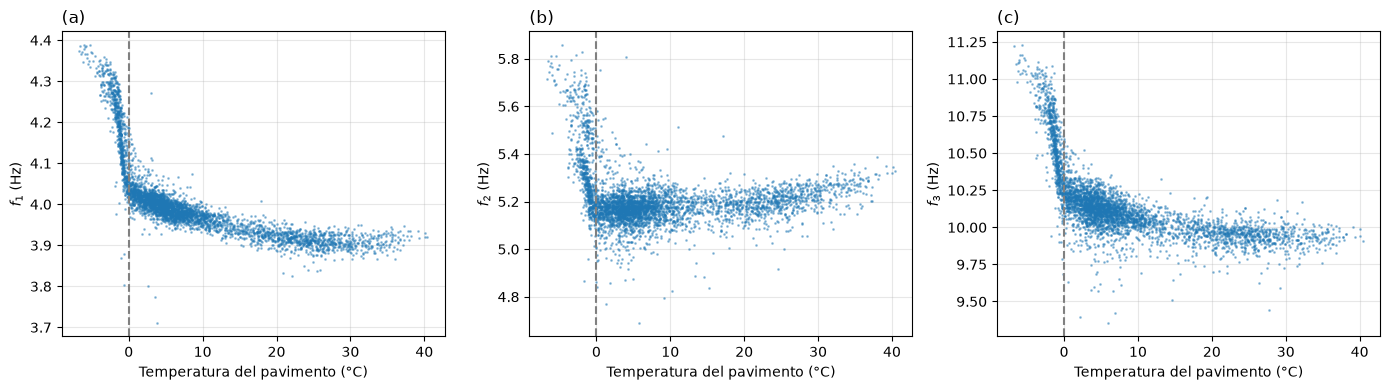

**Figura 1.** Frecuencia frente a la temperatura del pavimento en el entrenamiento: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [4]:
training_valid = data[(data["block"] == "Entrenamiento") & (data["status"] == "Válida")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, mode in enumerate(MODES):
    axes[i].plot(training_valid["T"], training_valid[f"f{mode}"], ".", markersize=2, alpha=0.4)
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"$f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 1, "Frecuencia frente a la temperatura del pavimento en el entrenamiento: (a) modo 1, (b) modo 2 "
            "y (c) modo 3. La línea discontinua marca 0 °C.")

- **Quiebre en 0 °C:** sobre 0 °C la relación es casi lineal y suave ($f_2$ casi no cambia); bajo 0 °C las tres frecuencias suben con fuerza, porque el asfalto se congela.
- **Dispersión bajo 0 °C:** con la misma temperatura, la frecuencia cambia mucho. Depende de cuánto tiempo y cuánto frío lleva el puente, lo que justifica las variables de historia de la sección 4.

---
<a id="sec4"></a>
## 4. Variables

Todas se construyen antes de comparar modelos, con todas las mediciones en orden de tiempo y usando solo la medición actual y las anteriores.

- **Media móvil de $w$ horas:**

$$
\bar{T}_{w,i} = \frac{1}{n_{w,i}} \sum_{j\,:\; t_i - w < t_j \le t_i} T_j
\tag{3}
$$

donde $T_j$ es la temperatura de la medición $j$, $t_j$ su hora y $n_{w,i}$ el número de mediciones en las últimas $w$ horas.

- **Horas seguidas bajo cero (variante A):** suma las horas mientras la medición y la anterior están bajo 0 °C; vuelve a 0 en cuanto la temperatura pasa de 0 °C.
- **Índice de congelamiento** (definición de la sección 10 del notebook actual), en °C·h:

$$
I_i = \max\left(0,\; I_{i-1} - T_i \, \Delta t_i\right)
\tag{4}
$$

donde $\Delta t_i$ son las horas desde la medición anterior. Crece bajo 0 °C, baja con el deshielo y nunca es negativo.

**Tabla 3.** Conjuntos de variables de entrada.

| Conjunto | Variables | Idea |
|---|---|---|
| A | $T$, $\bar{T}_6$, $\bar{T}_{12}$, $\bar{T}_{24}$, horas seguidas bajo cero | Temperatura y su historia, sin forma impuesta |
| F (físico) | $T$, $\bar{T}_{24}$, $\min(T, 0)$, $\sqrt{I}$ | Un término por mecanismo: rigidez, inercia térmica, quiebre del asfalto congelado y congelamiento acumulado |

In [5]:
# 1. Moving averages of the temperature (Eq. 3)
data["T_mean_6h"] = data.rolling("6h", on="start")["T"].mean()
data["T_mean_12h"] = data.rolling("12h", on="start")["T"].mean()
data["T_mean_24h"] = data.rolling("24h", on="start")["T"].mean()

# 2. Consecutive hours below 0 °C (variant A)
hours_below_zero = []
counter = 0
previous_T = np.nan
previous_start = None
for _, row in data.iterrows():
    if row["T"] < 0 and previous_T < 0:
        counter = counter + (row["start"] - previous_start).total_seconds() / 3600
    else:
        counter = 0
    hours_below_zero.append(counter)
    previous_T = row["T"]
    previous_start = row["start"]
data["hours_below_zero"] = hours_below_zero

# 3. Freezing index (Eq. 4)
freezing_index = []
index_value = 0
previous_start = None
for _, row in data.iterrows():
    if previous_start is not None and not np.isnan(row["T"]):
        hours = (row["start"] - previous_start).total_seconds() / 3600
        index_value = max(0, index_value - row["T"] * hours)
    freezing_index.append(index_value)
    previous_start = row["start"]
data["freezing_index"] = freezing_index

# 4. Other terms of set F
data["T_below_zero"] = np.minimum(data["T"], 0)
data["sqrt_freezing_index"] = np.sqrt(data["freezing_index"])

# 5. The two sets of input variables (Table 3)
FEATURE_SETS = {
    "A": ["T", "T_mean_6h", "T_mean_12h", "T_mean_24h", "hours_below_zero"],
    "F": ["T", "T_mean_24h", "T_below_zero", "sqrt_freezing_index"],
}

# 6. Frost in the last 72 h (used only for the two alarm limits of Section 10)
data["below_zero_flag"] = (data["T"] < 0).astype(float)
data["frost_last_72h"] = data.rolling("72h", on="start")["below_zero_flag"].max() == 1

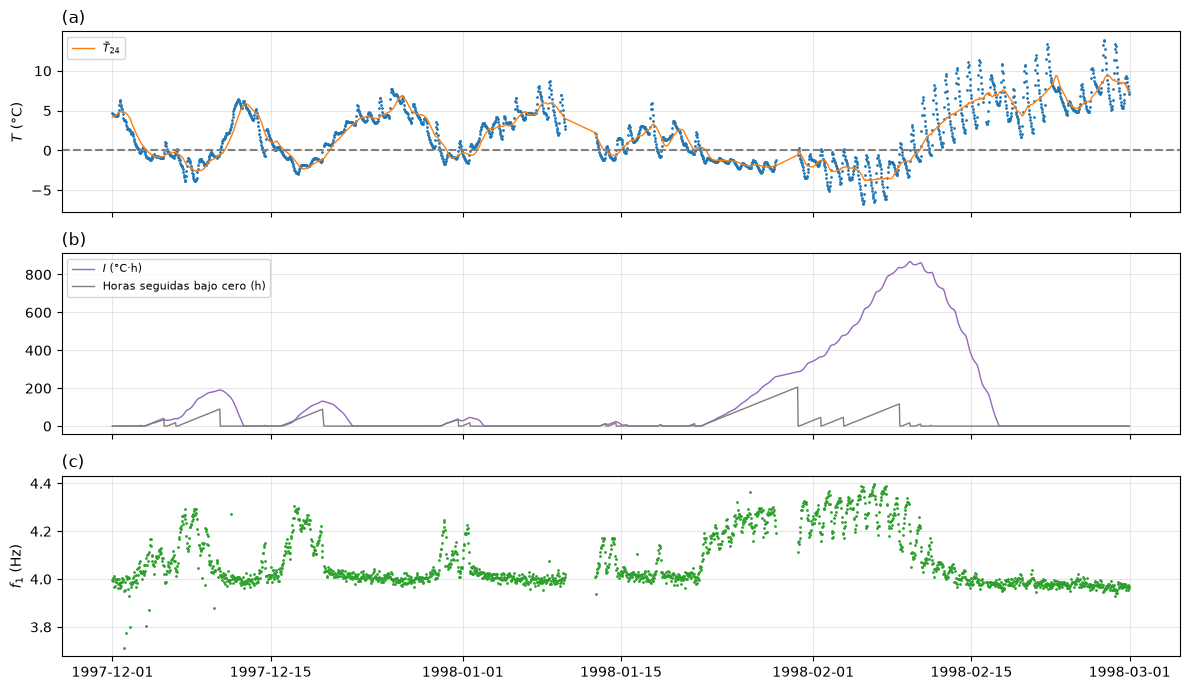

**Figura 2.** Invierno (01.12.1997 al 28.02.1998): (a) temperatura del pavimento y su media de 24 h, (b) índice de congelamiento (Ec. 4) y horas seguidas bajo cero, y (c) frecuencia del modo 1.

In [6]:
winter = data[(data["start"] >= "1997-12-01") & (data["start"] < "1998-03-01")]

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(winter["start"], winter["T"], ".", markersize=2)
axes[0].plot(winter["start"], winter["T_mean_24h"], "-", linewidth=1, color="tab:orange", label="$\\bar{T}_{24}$")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_ylabel("$T$ (°C)")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(winter["start"], winter["freezing_index"], "-", linewidth=1, color="tab:purple", label="$I$ (°C·h)")
axes[1].plot(winter["start"], winter["hours_below_zero"], "-", linewidth=1, color="tab:gray",
             label="Horas seguidas bajo cero (h)")
axes[1].legend(loc="upper left", fontsize=8)
axes[2].plot(winter["start"], winter["f1"], ".", markersize=2, color="tab:green")
axes[2].set_ylabel("$f_1$ (Hz)")
for i in range(3):
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 2, "Invierno (01.12.1997 al 28.02.1998): (a) temperatura del pavimento y su media de 24 h, "
            "(b) índice de congelamiento (Ec. 4) y horas seguidas bajo cero, y (c) frecuencia del modo 1.")

---
<a id="sec5"></a>
## 5. Referencia trivial

Predice siempre la media de la frecuencia de los folds de ajuste. Cualquier modelo útil tiene que bajar su RMSE.

La función `cv_predict` hace la validación cruzada por semanas de cualquier modelo: para cada fold, ajusta una copia nueva del modelo con los otros cuatro folds y predice el fold que quedó fuera. Devuelve las predicciones fuera del fold, el RMSE de validación de cada fold y el RMSE de entrenamiento de cada fold.

In [7]:
# Valid measurements of the training block
train_data = data[(data["block"] == "Entrenamiento") & (data["status"] == "Válida")].copy()
below_zero = train_data["T"] < 0


# RMSE (Eq. 2)
def rmse(residuals):
    return np.sqrt(np.mean(residuals ** 2))


# Cross-validation by weeks for one model, one set of variables and one mode
def cv_predict(model, features, mode):
    target = f"f{mode}"
    predictions = pd.Series(np.nan, index=train_data.index)
    fold_rmse = []
    train_rmse = []
    for fold in range(1, N_FOLDS + 1):
        fit_rows = train_data["fold"] != fold        # measurements used to fit the model
        val_rows = train_data["fold"] == fold        # measurements predicted (validation)

        fold_model = clone(model)                    # new, unfitted copy with the same settings
        fold_model.fit(train_data.loc[fit_rows, features], train_data.loc[fit_rows, target])

        predictions[val_rows] = fold_model.predict(train_data.loc[val_rows, features])
        fit_predictions = fold_model.predict(train_data.loc[fit_rows, features])

        fold_rmse.append(rmse(train_data.loc[val_rows, target] - predictions[val_rows]))
        train_rmse.append(rmse(train_data.loc[fit_rows, target] - fit_predictions))
    return predictions, fold_rmse, train_rmse


rows = []
for mode in MODES:
    predictions, fold_rmse, train_rmse = cv_predict(DummyRegressor(strategy="mean"), FEATURE_SETS["A"], mode)
    residuals = train_data[f"f{mode}"] - predictions
    rows.append({"Modo": mode, "RMSE total (Hz)": rmse(residuals),
                 "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
                 "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero])})
show_table(pd.DataFrame(rows), 4, "RMSE (Ec. 2) de la validación cruzada por semanas de la referencia trivial (media).")

**Tabla 4.** RMSE (Ec. 2) de la validación cruzada por semanas de la referencia trivial (media).

Modo,RMSE total (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz)
1,0.099,0.203,0.058
2,0.117,0.230,0.075
3,0.249,0.496,0.155


---
<a id="sec6"></a>
## 6. Escalera de modelos

De menos a más flexible. Cada modelo se prueba con los conjuntos A y F.

**a. Regresión lineal:**

$$
\hat{f} = \beta_0 + \sum_{j=1}^{p} \beta_j x_j
\tag{5}
$$

donde $x_j$ son las $p$ variables del conjunto y $\beta_j$ sus coeficientes, ajustados por mínimos cuadrados.

**c. Modelo físico:** es la regresión lineal (Ec. 5) con el conjunto F:

$$
\hat{f} = \beta_0 + \beta_1 T + \beta_2 \bar{T}_{24} + \beta_3 \min(T, 0) + \beta_4 \sqrt{I}
\tag{6}
$$

Por eso "regresión lineal con F" y "modelo físico" son el mismo modelo, y aparece una sola vez en las comparaciones.

**b. Ridge:** regresión lineal con las variables estandarizadas y una penalización a los coeficientes grandes:

$$
\min_{\boldsymbol{\beta}} \; \sum_{i=1}^{n} \left(f_i - \hat{f}_i\right)^2 + \alpha \sum_{j=1}^{p} \beta_j^2
\tag{7}
$$

donde $\alpha \ge 0$ controla la penalización. Sirve cuando las variables se mueven juntas (como $T$ y sus medias móviles).

**d. SVR con kernel RBF** (*Support Vector Regression*, *Radial Basis Function*): una curva suave, sin forma impuesta:

$$
\hat{f}(\mathbf{x}) = b + \sum_{i} a_i \exp\left(-\gamma \lVert \mathbf{x} - \mathbf{x}_i \rVert^2\right)
\tag{8}
$$

donde $\mathbf{x}_i$ son mediciones del ajuste, $a_i$ y $b$ se ajustan, $\gamma$ fija qué tan local es cada término, $C$ penaliza los errores y los errores menores que $\varepsilon$ (Hz) no se penalizan.

**e. Random forest:** promedio de 200 árboles de regresión, cada uno ajustado con una muestra al azar de las mediciones:

$$
\hat{f}(\mathbf{x}) = \frac{1}{B} \sum_{b=1}^{B} h_b(\mathbf{x})
\tag{9}
$$

donde $h_b$ es el árbol $b$ y $B = 200$. No extrapola: fuera del rango del ajuste predice el valor de la hoja más cercana.

**Escalado sin fuga de información:** Ridge y SVR van en un `Pipeline` con `StandardScaler`. Como `cv_predict` ajusta una copia nueva del `Pipeline` en cada fold, la media y la desviación del escalado salen solo de los folds de ajuste.

In [8]:
# Builds a new model from its name and hyperparameters
def build_model(model_name, params):
    if model_name == "Lineal":
        return LinearRegression()
    elif model_name == "Ridge":
        return Pipeline([("scale", StandardScaler()), ("ridge", Ridge(alpha=params["alpha"]))])
    elif model_name == "SVR":
        return Pipeline([("scale", StandardScaler()),
                         ("svr", SVR(kernel="rbf", C=params["C"], gamma=params["gamma"], epsilon=params["epsilon"]))])
    elif model_name == "Random forest":
        return RandomForestRegressor(n_estimators=200, min_samples_leaf=params["min_samples_leaf"],
                                     max_features=params["max_features"], random_state=SEED, n_jobs=-1)


# Coefficients of the physical model (Eq. 6) fitted with all the training measurements
rows = []
for mode in MODES:
    model = LinearRegression()
    model.fit(train_data[FEATURE_SETS["F"]], train_data[f"f{mode}"])
    rows.append({
        "Modo": mode,
        "β0 (Hz)": model.intercept_,
        "β1, T (Hz/°C)": model.coef_[0],
        "β2, T media 24 h (Hz/°C)": model.coef_[1],
        "β3, min(T, 0) (Hz/°C)": model.coef_[2],
        "β4, √I (Hz/√(°C·h))": model.coef_[3],
    })
show_table(pd.DataFrame(rows), 5, "Coeficientes del modelo físico (Ec. 6) ajustado con todo el entrenamiento.", decimals=4)

**Tabla 5.** Coeficientes del modelo físico (Ec. 6) ajustado con todo el entrenamiento.

Modo,β0 (Hz),"β1, T (Hz/°C)","β2, T media 24 h (Hz/°C)","β3, min(T, 0) (Hz/°C)","β4, √I (Hz/√(°C·h))"
1,4.0198,-0.0007,-0.0038,-0.0736,0.0026
2,5.1396,0.0042,-0.0015,-0.0747,0.0086
3,10.1688,-0.0038,-0.0057,-0.1847,0.0064


Los mismos signos que en el notebook actual: $\beta_3 < 0$ (la frecuencia sube más rápido bajo 0 °C) y $\beta_4 > 0$ (más frío acumulado, más rigidez) en los tres modos.

---
<a id="sec7"></a>
## 7. Ajuste de hiperparámetros

Cada modelo flexible, con cada conjunto y en cada modo, tiene su propia búsqueda con la validación cruzada por semanas. Se elige la combinación de menor RMSE de validación.

**Tabla 6.** Grillas de búsqueda.

| Modelo | Hiperparámetro | Valores |
|---|---|---|
| Ridge | $\alpha$ | 0.01, 0.1, 1, 10, 100, 1000 |
| SVR | $C$ | 0.1, 1, 10, 100 |
| | $\gamma$ | 0.003, 0.01, 0.05, 0.2, 1 |
| | $\varepsilon$ (Hz) | 0.01, 0.03, 0.06, 0.1 |
| Random forest | `min_samples_leaf` | 1, 5, 10, 20, 50 |
| | `max_features` | 1 al número de variables (1–5 con A, 1–4 con F) |

- **Corrección principal respecto al notebook actual:** el random forest con F tiene su propia búsqueda, en lugar de usar los hiperparámetros de la variante A.
- Los resultados se guardan en CSV en `tuning_v2/` para no recalcular. Si se cambia una grilla, hay que borrar su CSV.
- **Limitación:** los hiperparámetros se eligen y el error se estima con la misma validación cruzada, así que el RMSE de los modelos ajustados es algo optimista.

In [9]:
# 1. Grids (Table 6)
GRIDS = {"Ridge": [], "SVR": [], "Random forest A": [], "Random forest F": []}
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    GRIDS["Ridge"].append({"alpha": alpha})
for C in [0.1, 1, 10, 100]:
    for gamma in [0.003, 0.01, 0.05, 0.2, 1]:
        for epsilon in [0.01, 0.03, 0.06, 0.1]:
            GRIDS["SVR"].append({"C": C, "gamma": gamma, "epsilon": epsilon})
for set_name in ["A", "F"]:
    for min_samples_leaf in [1, 5, 10, 20, 50]:
        for max_features in range(1, len(FEATURE_SETS[set_name]) + 1):
            GRIDS[f"Random forest {set_name}"].append({"min_samples_leaf": min_samples_leaf,
                                                       "max_features": max_features})

FILE_NAMES = {"Ridge": "ridge", "SVR": "svr", "Random forest": "rf"}


# 2. Search for one model and one set: validation RMSE of every combination in every mode.
#    The result is saved in a CSV and read from it the next time.
def tune(model_name, set_name):
    file = f"{TUNING_FOLDER}/{FILE_NAMES[model_name]}_tuning_{set_name}.csv"
    if os.path.exists(file):
        return pd.read_csv(file)

    if model_name == "Random forest":
        grid = GRIDS[f"Random forest {set_name}"]
    else:
        grid = GRIDS[model_name]

    rows = []
    for mode in MODES:
        for params in grid:
            model = build_model(model_name, params)
            predictions, fold_rmse, train_rmse = cv_predict(model, FEATURE_SETS[set_name], mode)
            row = {"mode": mode}
            row.update(params)
            row["rmse"] = rmse(train_data[f"f{mode}"] - predictions)
            rows.append(row)
    table = pd.DataFrame(rows)
    table.to_csv(file, index=False)
    return table


# 3. Best combination of one mode (smallest validation RMSE)
def best_params(table, model_name, mode):
    mode_rows = table[table["mode"] == mode]
    best = mode_rows.loc[mode_rows["rmse"].idxmin()]
    if model_name == "Ridge":
        return {"alpha": float(best["alpha"])}
    elif model_name == "SVR":
        return {"C": float(best["C"]), "gamma": float(best["gamma"]), "epsilon": float(best["epsilon"])}
    else:
        return {"min_samples_leaf": int(best["min_samples_leaf"]), "max_features": int(best["max_features"])}


# 4. Run the searches and keep the best combination of each model, set and mode
BEST_PARAMS = {}
rows = []
for model_name in ["Ridge", "SVR", "Random forest"]:
    for set_name in ["A", "F"]:
        table = tune(model_name, set_name)
        for mode in MODES:
            params = best_params(table, model_name, mode)
            BEST_PARAMS[(model_name, set_name, mode)] = params
            row = {"Modelo": model_name, "Conjunto": set_name, "Modo": mode,
                   "Hiperparámetros": ", ".join(f"{name} = {value:g}" for name, value in params.items()),
                   "RMSE de validación (Hz)": table.loc[table["mode"] == mode, "rmse"].min()}
            rows.append(row)
for set_name in ["A", "F"]:
    for mode in MODES:
        BEST_PARAMS[("Lineal", set_name, mode)] = {}

show_table(pd.DataFrame(rows), 7, "Mejor combinación de hiperparámetros de cada modelo, conjunto y modo (menor RMSE "
           "de la validación cruzada por semanas, Ec. 2).", decimals=4)

**Tabla 7.** Mejor combinación de hiperparámetros de cada modelo, conjunto y modo (menor RMSE de la validación cruzada por semanas, Ec. 2).

Modelo,Conjunto,Modo,Hiperparámetros,RMSE de validación (Hz)
Ridge,A,1,alpha = 100,0.0553
Ridge,A,2,alpha = 10,0.1078
Ridge,A,3,alpha = 1,0.1619
Ridge,F,1,alpha = 0.01,0.0364
Ridge,F,2,alpha = 0.01,0.0707
Ridge,F,3,alpha = 0.01,0.1168
SVR,A,1,"C = 10, gamma = 0.2, epsilon = 0.03",0.0330
SVR,A,2,"C = 1, gamma = 1, epsilon = 0.03",0.0874
SVR,A,3,"C = 10, gamma = 0.2, epsilon = 0.03",0.1114
SVR,F,1,"C = 1, gamma = 0.003, epsilon = 0.01",0.0266


---
<a id="sec8"></a>
## 8. Comparación de modelos

Cada candidato se vuelve a validar con sus hiperparámetros propios. Para cada uno se calcula:

- RMSE de validación total, bajo 0 °C y sobre 0 °C (Ec. 2, residuos fuera del fold);
- desviación estándar (DE) del RMSE de validación entre los 5 folds, y su error estándar, $\text{EE} = \text{DE}/\sqrt{5}$;
- RMSE de entrenamiento (promedio de los 5 folds). Si es mucho menor que el de validación, el modelo se sobreajusta.

In [10]:
# Candidates: (key, model name, set of variables). The linear regression with F is the physical model.
CANDIDATES = [
    ("linear_A", "Lineal", "A"),
    ("physical_F", "Lineal", "F"),
    ("ridge_A", "Ridge", "A"),
    ("ridge_F", "Ridge", "F"),
    ("svr_A", "SVR", "A"),
    ("svr_F", "SVR", "F"),
    ("rf_A", "Random forest", "A"),
    ("rf_F", "Random forest", "F"),
]
LABELS = {"linear_A": "Regresión lineal", "physical_F": "Modelo físico", "ridge_A": "Ridge", "ridge_F": "Ridge",
          "svr_A": "SVR", "svr_F": "SVR", "rf_A": "Random forest", "rf_F": "Random forest"}

# Validation of every candidate with its own hyperparameters
comparison_rows = []
for key, model_name, set_name in CANDIDATES:
    for mode in MODES:
        params = BEST_PARAMS[(model_name, set_name, mode)]
        model = build_model(model_name, params)
        predictions, fold_rmse, train_rmse = cv_predict(model, FEATURE_SETS[set_name], mode)

        # Out-of-fold residuals (Eq. 1), used later by the detection system
        residuals = train_data[f"f{mode}"] - predictions
        train_data[f"res_{key}_f{mode}"] = residuals

        comparison_rows.append({
            "key": key,
            "Modo": mode,
            "Modelo": LABELS[key],
            "Conjunto": set_name,
            "RMSE validación (Hz)": rmse(residuals),
            "DE entre folds (Hz)": np.std(fold_rmse, ddof=1),
            "EE (Hz)": np.std(fold_rmse, ddof=1) / np.sqrt(N_FOLDS),
            "RMSE bajo 0 °C (Hz)": rmse(residuals[below_zero]),
            "RMSE sobre 0 °C (Hz)": rmse(residuals[~below_zero]),
            "RMSE entrenamiento (Hz)": np.mean(train_rmse),
        })
comparison = pd.DataFrame(comparison_rows)

for i, mode in enumerate(MODES):
    mode_table = comparison[comparison["Modo"] == mode].drop(columns=["key", "Modo"])
    show_table(mode_table, 8 + i, f"Comparación de modelos y conjuntos de variables para $f_{mode}$ (validación "
               "cruzada por semanas).", decimals=4)

**Tabla 8.** Comparación de modelos y conjuntos de variables para $f_1$ (validación cruzada por semanas).

Modelo,Conjunto,RMSE validación (Hz),DE entre folds (Hz),EE (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz),RMSE entrenamiento (Hz)
Regresión lineal,A,0.0554,0.0132,0.0059,0.1179,0.0289,0.0530
Modelo físico,F,0.0364,0.0072,0.0032,0.0679,0.0255,0.0311
Ridge,A,0.0553,0.0132,0.0059,0.1178,0.0290,0.0531
Ridge,F,0.0364,0.0072,0.0032,0.0679,0.0255,0.0311
SVR,A,0.0330,0.0038,0.0017,0.0641,0.0216,0.0256
SVR,F,0.0266,0.0052,0.0023,0.0470,0.0200,0.0245
Random forest,A,0.0282,0.0062,0.0028,0.0524,0.0199,0.0195
Random forest,F,0.0256,0.0042,0.0019,0.0460,0.0188,0.0188


**Tabla 9.** Comparación de modelos y conjuntos de variables para $f_2$ (validación cruzada por semanas).

Modelo,Conjunto,RMSE validación (Hz),DE entre folds (Hz),EE (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz),RMSE entrenamiento (Hz)
Regresión lineal,A,0.1078,0.0346,0.0155,0.2147,0.0673,0.0990
Modelo físico,F,0.0707,0.0119,0.0053,0.0987,0.0635,0.0647
Ridge,A,0.1078,0.0347,0.0155,0.2146,0.0674,0.0990
Ridge,F,0.0707,0.0119,0.0053,0.0987,0.0635,0.0647
SVR,A,0.0874,0.0241,0.0108,0.1579,0.0639,0.0640
SVR,F,0.0622,0.0049,0.0022,0.0798,0.0579,0.0566
Random forest,A,0.0863,0.0259,0.0116,0.1531,0.0646,0.0602
Random forest,F,0.0679,0.0081,0.0036,0.0958,0.0607,0.0456


**Tabla 10.** Comparación de modelos y conjuntos de variables para $f_3$ (validación cruzada por semanas).

Modelo,Conjunto,RMSE validación (Hz),DE entre folds (Hz),EE (Hz),RMSE bajo 0 °C (Hz),RMSE sobre 0 °C (Hz),RMSE entrenamiento (Hz)
Regresión lineal,A,0.1619,0.0371,0.0166,0.3145,0.1062,0.1556
Modelo físico,F,0.1168,0.0136,0.0061,0.1717,0.1019,0.1086
Ridge,A,0.1619,0.0371,0.0166,0.3146,0.1062,0.1556
Ridge,F,0.1168,0.0136,0.0061,0.1717,0.1019,0.1086
SVR,A,0.1114,0.0095,0.0042,0.1749,0.0931,0.1013
SVR,F,0.1033,0.0052,0.0023,0.1363,0.0951,0.0990
Random forest,A,0.1062,0.0084,0.0038,0.1532,0.0937,0.0831
Random forest,F,0.1006,0.0043,0.0019,0.1323,0.0928,0.0845


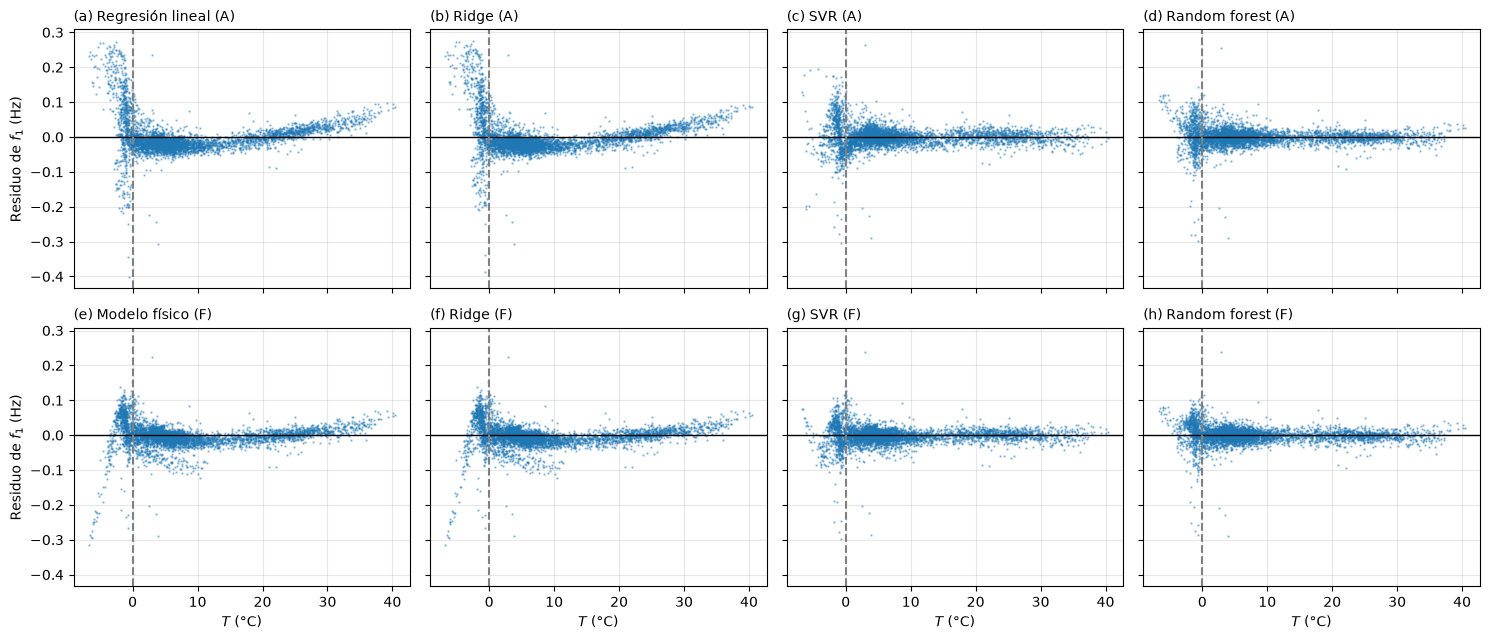

**Figura 3.** Residuos fuera del fold (Ec. 1) de $f_1$ frente a la temperatura del pavimento, por modelo (columnas) y conjunto de variables (fila superior A, inferior F). La línea discontinua marca 0 °C.

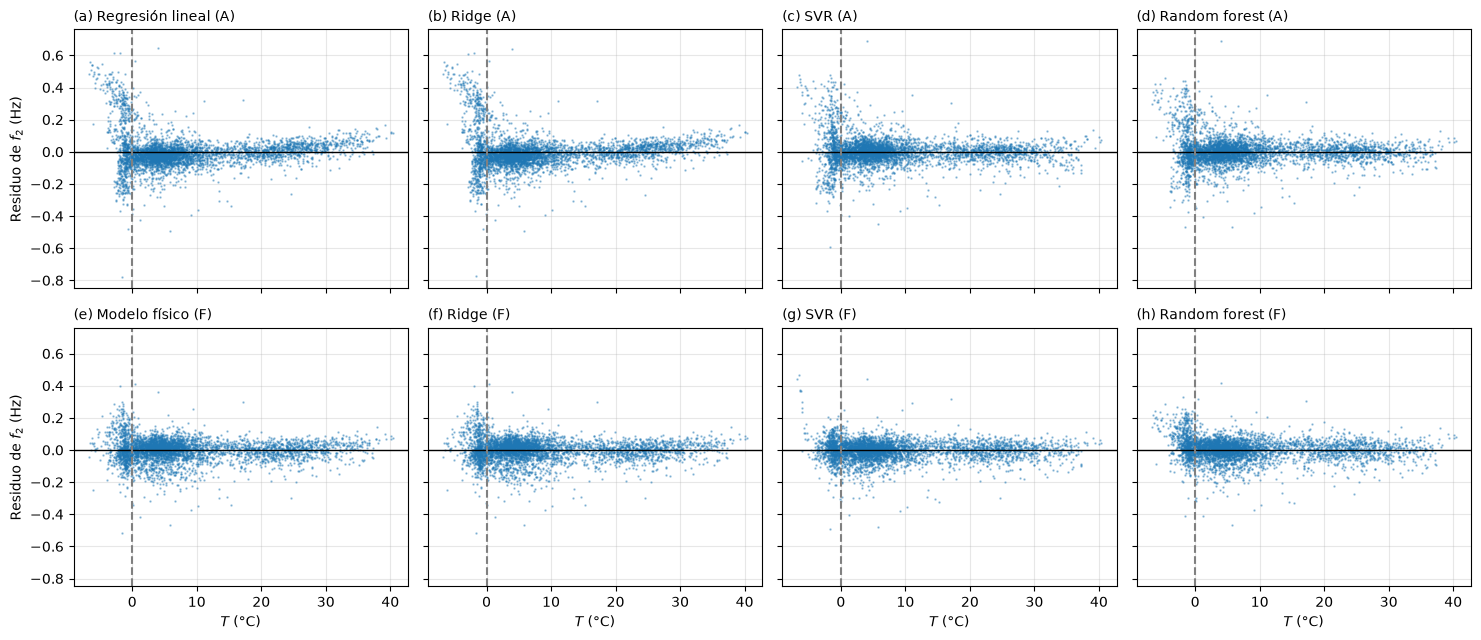

**Figura 4.** Residuos fuera del fold (Ec. 1) de $f_2$ frente a la temperatura del pavimento, por modelo (columnas) y conjunto de variables (fila superior A, inferior F). La línea discontinua marca 0 °C.

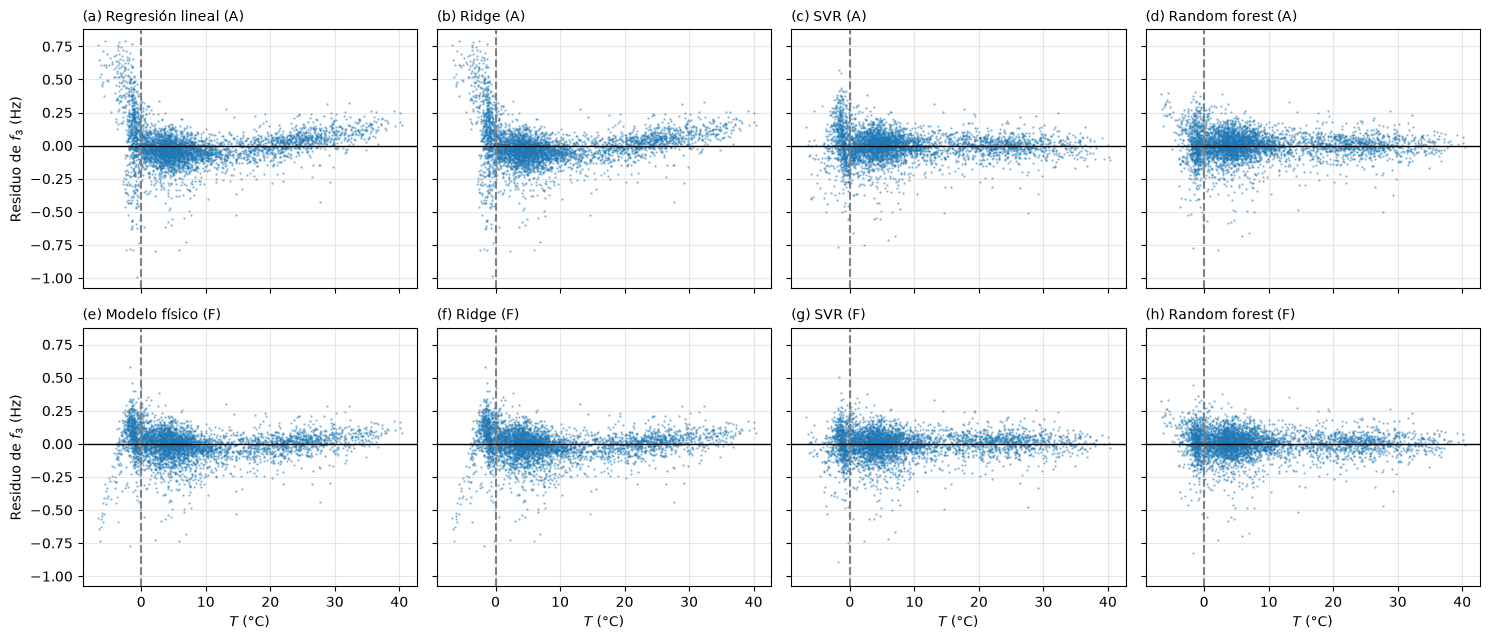

**Figura 5.** Residuos fuera del fold (Ec. 1) de $f_3$ frente a la temperatura del pavimento, por modelo (columnas) y conjunto de variables (fila superior A, inferior F). La línea discontinua marca 0 °C.

In [11]:
# Residuals against the temperature: rows = sets A and F, columns = models
GRID_KEYS = [["linear_A", "ridge_A", "svr_A", "rf_A"],
             ["physical_F", "ridge_F", "svr_F", "rf_F"]]

for mode in MODES:
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True, sharey=True)
    for row in range(2):
        for column in range(4):
            key = GRID_KEYS[row][column]
            ax = axes[row][column]
            ax.plot(train_data["T"], train_data[f"res_{key}_f{mode}"], ".", markersize=1.5, alpha=0.4)
            ax.axhline(0, color="black", linewidth=1)
            ax.axvline(0, color="gray", linestyle="--")
            set_name = key[-1]
            ax.set_title(f"{PANEL_LABELS[4 * row + column]} {LABELS[key]} ({set_name})", loc="left", fontsize=10)
            ax.grid(alpha=0.3)
            if row == 1:
                ax.set_xlabel("$T$ (°C)")
            if column == 0:
                ax.set_ylabel(f"Residuo de $f_{mode}$ (Hz)")
    fig.tight_layout()
    show_figure(fig, 3 + mode - 1, f"Residuos fuera del fold (Ec. 1) de $f_{mode}$ frente a la temperatura del "
                "pavimento, por modelo (columnas) y conjunto de variables (fila superior A, inferior F). La línea "
                "discontinua marca 0 °C.")

**Resultados:**

- **Verificación:** la regresión lineal A (0.055 / 0.108 / 0.162 Hz) y el random forest A (0.028 / 0.086 / 0.106 Hz) dan lo mismo que las Tablas 8 y 10 del notebook actual; el modelo físico, lo mismo que su sección 10.
- **El conjunto F mejora a todos los modelos en los tres modos.** La mejora más grande está bajo 0 °C: en $f_1$, la regresión lineal baja de 0.118 Hz (A) a 0.068 Hz (F).
- **Ridge no aporta:** con F eligió alpha = 0.01, que equivale a la regresión lineal (mismo RMSE que el modelo físico); con A da lo mismo que la lineal. Hay pocas variables y muchos datos, así que no hace falta regularizar.
- **Los mejores son SVR F y random forest F:** $f_1$ random forest F (0.0256 Hz), $f_2$ SVR F (0.0622 Hz) y $f_3$ random forest F (0.1006 Hz). Los errores bajo 0 °C siguen siendo los más grandes (Figuras 3 a 5).
- **Sobreajuste:** el random forest tiene un RMSE de entrenamiento mucho menor que el de validación (en $f_2$ con F, 0.046 frente a 0.068 Hz). En el SVR F y el modelo físico la diferencia es menor (en $f_2$, 0.057 frente a 0.062 Hz y 0.065 frente a 0.071 Hz).
- **Bordes de la grilla del SVR:** algunos óptimos quedan en el borde (γ = 0.003 en F). Una prueba fuera de la grilla (γ hasta 0.0003, C hasta 1000, ε hasta 0.15) no bajó el RMSE en más de 0.0001 Hz, así que la grilla basta.
- Estos RMSE son **optimistas**: los hiperparámetros se eligieron con los mismos folds con que se evalúan.

---
<a id="sec9"></a>
## 9. Selección del modelo

Se decide solo con las Tablas 8 a 10, antes de mirar la prueba.

**Regla de un error estándar,** aplicada a cada modo por separado (cada modo tiene su propio residuo, y la distancia de Mahalanobis los combina después):

1. Se busca el candidato de menor RMSE de validación, $\text{RMSE}_{\min}$, con error estándar $\text{EE}_{\min}$.
2. Se elige el candidato **más simple** que cumpla

$$
\text{RMSE}_j \le \text{RMSE}_{\min} + \text{EE}_{\min}
\tag{10}
$$

donde $\text{RMSE}_j$ es el RMSE de validación del candidato $j$ y $\text{EE}_{\min} = \text{DE}_{\min}/\sqrt{5}$, con $\text{DE}_{\min}$ la desviación estándar de su RMSE entre los 5 folds.

**Orden de simplicidad** (de más simple a más complejo): modelo físico (5 coeficientes) → regresión lineal A (6) → Ridge F → Ridge A (un hiperparámetro) → SVR F → SVR A → random forest F → random forest A. Con el mismo modelo, F va antes que A porque tiene una variable menos.

In [12]:
SIMPLICITY_ORDER = ["physical_F", "linear_A", "ridge_F", "ridge_A", "svr_F", "svr_A", "rf_F", "rf_A"]

CHOSEN = {}
rows = []
for mode in MODES:
    mode_table = comparison[comparison["Modo"] == mode]

    # 1. Best candidate
    best = mode_table.loc[mode_table["RMSE validación (Hz)"].idxmin()]
    threshold = best["RMSE validación (Hz)"] + best["EE (Hz)"]          # Eq. 10

    # 2. Simplest candidate below the threshold
    for key in SIMPLICITY_ORDER:
        candidate_rmse = mode_table.loc[mode_table["key"] == key, "RMSE validación (Hz)"].iloc[0]
        if candidate_rmse <= threshold:
            CHOSEN[mode] = key
            break

    chosen_rmse = mode_table.loc[mode_table["key"] == CHOSEN[mode], "RMSE validación (Hz)"].iloc[0]
    rows.append({
        "Modo": mode,
        "Mejor candidato": f"{LABELS[best['key']]} ({best['Conjunto']})",
        "RMSE mínimo (Hz)": best["RMSE validación (Hz)"],
        "EE del mejor (Hz)": best["EE (Hz)"],
        "Umbral, Ec. 10 (Hz)": threshold,
        "Elegido": f"{LABELS[CHOSEN[mode]]} ({CHOSEN[mode][-1]})",
        "RMSE del elegido (Hz)": chosen_rmse,
    })
show_table(pd.DataFrame(rows), 11, "Selección del modelo de cada modo con la regla de un error estándar (Ec. 10).",
           decimals=4)

**Tabla 11.** Selección del modelo de cada modo con la regla de un error estándar (Ec. 10).

Modo,Mejor candidato,RMSE mínimo (Hz),EE del mejor (Hz),"Umbral, Ec. 10 (Hz)",Elegido,RMSE del elegido (Hz)
1,Random forest (F),0.0256,0.0019,0.0275,SVR (F),0.0266
2,SVR (F),0.0622,0.0022,0.0644,SVR (F),0.0622
3,Random forest (F),0.1006,0.0019,0.1025,Random forest (F),0.1006


**Decisión (escrita antes de usar la prueba):**

- $f_1$: el mejor es el random forest F (0.0256 Hz); el SVR F (0.0266 Hz) queda bajo el umbral (0.0275 Hz) y es más simple → **SVR F**.
- $f_2$: el SVR F es el mejor → **SVR F**.
- $f_3$: el mejor es el random forest F (0.1006 Hz); el SVR F (0.1033 Hz) queda apenas sobre el umbral (0.1025 Hz) → **random forest F**.

El sistema usa el SVR F en $f_1$ y $f_2$ y el random forest F en $f_3$, todos con el conjunto F.

**Sensibilidad de la regla:** con la DE en lugar del EE (umbral más amplio), $f_1$ y $f_2$ no cambian, pero $f_3$ pasaría al SVR F (0.1033 ≤ 0.1049 Hz). La elección de $f_3$ entre SVR F y random forest F está en el límite: la diferencia es 0.003 Hz.

---
<a id="sec10"></a>
## 10. Sistema de detección con el modelo elegido

El mismo sistema de las secciones 7 y 8 del notebook actual, con el modelo elegido en cada modo:

1. **Residuos del entrenamiento:** los fuera del fold de la sección 8, con los hiperparámetros propios del modelo elegido.
2. **Residuos de la prueba:** modelo elegido ajustado con todo el entrenamiento.
3. **Índice de daño:** distancia de Mahalanobis, con la media $\boldsymbol{\mu}$ y la covarianza $\boldsymbol{\Sigma}$ de los residuos del entrenamiento:

$$
d_i = \sqrt{(\mathbf{r}_i - \boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1} (\mathbf{r}_i - \boldsymbol{\mu})}
\tag{11}
$$

donde $\mathbf{r}_i = [r_{1,i}, r_{2,i}, r_{3,i}]$ son los residuos de los tres modos de la medición $i$.

4. **EWMA** con $\lambda = 0.1$, fijado de antemano, empezando en la media de $d$ del entrenamiento:

$$
z_i = \lambda\, d_i + (1 - \lambda)\, z_{i-1}
\tag{12}
$$

5. **Límites** (UCL, *Upper Control Limit*), solo con el entrenamiento:

$$
\text{UCL} = \max_{i \,\in\, \text{entrenamiento}} z_i
\tag{13}
$$

Con un límite, el máximo de todo el entrenamiento; con dos límites, un máximo para las mediciones con helada en las 72 h anteriores y otro para las demás.

6. **Evaluación en la prueba, una sola vez.**

In [13]:
# 1. Valid measurements of the two test blocks (first use of the test blocks)
test_data = data[((data["block"] == "Prueba, puente sano") | (data["block"] == "Prueba, con daño"))
                 & (data["status"] == "Válida")].copy()
is_healthy = (test_data["block"] == "Prueba, puente sano").to_numpy()
is_damaged = (test_data["block"] == "Prueba, con daño").to_numpy()
test_times = test_data["start"].to_numpy()
labels = is_damaged.astype(int)                  # 1 = damaged, 0 = healthy (for the ROC curve)
CANDIDATE_INFO = {}
for key, model_name, set_name in CANDIDATES:
    CANDIDATE_INFO[key] = (model_name, set_name)


# 2. Test residuals (Eq. 1) of one candidate, fitted with all the training measurements
def test_residuals(key, mode):
    model_name, set_name = CANDIDATE_INFO[key]
    model = build_model(model_name, BEST_PARAMS[(model_name, set_name, mode)])
    model.fit(train_data[FEATURE_SETS[set_name]], train_data[f"f{mode}"])
    return test_data[f"f{mode}"] - model.predict(test_data[FEATURE_SETS[set_name]])


# 3. Mahalanobis distance (Eq. 11) of every row of a table of residuals
def mahalanobis(residuals, mean, cov_inv):
    distances = []
    for r in residuals:
        difference = r - mean
        distances.append(np.sqrt(difference @ cov_inv @ difference))
    return np.array(distances)


# 4. EWMA (Eq. 12)
def ewma(values, lam, start_value):
    smoothed = []
    z = start_value
    for d in values:
        z = lam * d + (1 - lam) * z
        smoothed.append(z)
    return np.array(smoothed)


# 5. Whole system: damage index, EWMA and limits (Eq. 11 to 13)
def detection_system(train_residuals, test_residuals, lam, two_limits):
    mean = train_residuals.mean(axis=0)
    cov_inv = np.linalg.inv(np.cov(train_residuals, rowvar=False))
    train_d = mahalanobis(train_residuals, mean, cov_inv)
    test_d = mahalanobis(test_residuals, mean, cov_inv)

    train_z = ewma(train_d, lam, train_d.mean())
    test_z = ewma(test_d, lam, train_d.mean())

    train_frost = train_data["frost_last_72h"].to_numpy()
    if two_limits:
        limit_frost = train_z[train_frost].max()
        limit_no_frost = train_z[~train_frost].max()
        test_limit = np.where(test_data["frost_last_72h"], limit_frost, limit_no_frost)
    else:
        test_limit = np.full(len(test_d), train_z.max())
    return train_z, test_d, test_z, test_limit


# 6. False alarms and detection of the damage
def alarm_summary(test_z, test_limit):
    alarm = test_z > test_limit
    previous_alarm = np.concatenate([[False], alarm[:-1]])
    new_alarm = alarm & ~previous_alarm          # an alarm starts when z goes above the limit

    damage_alarm_times = test_times[alarm & is_damaged]
    if len(damage_alarm_times) > 0:
        first_alarm = pd.Timestamp(damage_alarm_times[0])
        first_alarm_text = first_alarm.strftime("%d.%m.%Y %H:%M")
        delay_hours = (first_alarm - DAMAGE_START).total_seconds() / 3600
    else:
        first_alarm_text = "Sin alarma"
        delay_hours = np.nan
    return {
        "Falsas alarmas (puente sano)": new_alarm[is_healthy].sum(),
        "Horas en falsa alarma": alarm[is_healthy].sum(),
        "Primera alarma con daño": first_alarm_text,
        "Retraso de detección (h)": delay_hours,
        "% de horas con daño en alarma": 100 * alarm[is_damaged].mean(),
    }

In [14]:
LAMBDA = 0.1

# 1. Residuals of the chosen model of each mode: out-of-fold in training, final model in the test
chosen_train = np.column_stack([train_data[f"res_{CHOSEN[mode]}_f{mode}"] for mode in MODES])
chosen_test = np.column_stack([test_residuals(CHOSEN[mode], mode) for mode in MODES])

# 2. System with one and with two limits, and evaluation in the test blocks
rows = []
chosen_results = {}
for limit_name, two_limits in [("Un límite", False), ("Dos límites", True)]:
    train_z, test_d, test_z, test_limit = detection_system(chosen_train, chosen_test, LAMBDA, two_limits)
    chosen_results[limit_name] = (train_z, test_d, test_z, test_limit)
    row = {"Límite": limit_name, "UCL en la prueba": test_limit[0]}       # no frost in the test blocks
    row.update(alarm_summary(test_z, test_limit))
    row["AUC de d"] = roc_auc_score(labels, test_d)
    row["AUC de z"] = roc_auc_score(labels, test_z)
    rows.append(row)

train_frost = train_data["frost_last_72h"].to_numpy()
train_z = chosen_results["Dos límites"][0]
print(f"Limits: one = {train_z.max():.2f}, frost = {train_z[train_frost].max():.2f}, "
      f"no frost = {train_z[~train_frost].max():.2f}")
show_table(pd.DataFrame(rows), 12, "Detección con el modelo elegido (λ = 0.1): falsas alarmas en la prueba con el "
           "puente sano, retraso de detección, horas con daño en alarma y área bajo la curva ROC.", decimals=2)

Limits: one = 3.95, frost = 3.95, no frost = 2.88


**Tabla 12.** Detección con el modelo elegido (λ = 0.1): falsas alarmas en la prueba con el puente sano, retraso de detección, horas con daño en alarma y área bajo la curva ROC.

Límite,UCL en la prueba,Falsas alarmas (puente sano),Horas en falsa alarma,Primera alarma con daño,Retraso de detección (h),% de horas con daño en alarma,AUC de d,AUC de z
Un límite,3.95,1,10,13.08.1998 06:00,40.75,96.76,0.98,0.99
Dos límites,2.88,3,26,12.08.1998 08:00,18.75,98.79,0.98,0.99


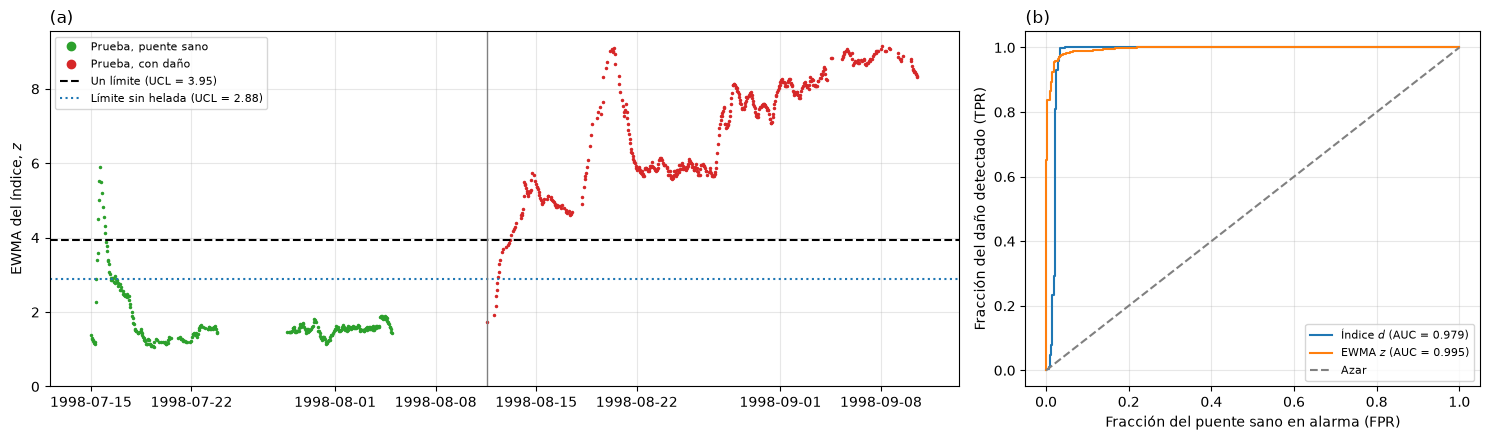

**Figura 6.** Sistema con el modelo elegido: (a) EWMA (Ec. 12, λ = 0.1) en los bloques de prueba con los límites (Ec. 13); la línea vertical marca el comienzo del daño. (b) Curvas ROC del índice y de la EWMA en la prueba (TPR: mediciones con daño sobre el límite; FPR: mediciones sanas sobre el límite).

In [15]:
train_z, test_d, test_z, test_limit = chosen_results["Dos límites"]
one_limit = chosen_results["Un límite"][3][0]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})

# (a) EWMA in the test blocks
axes[0].plot(test_times[is_healthy], test_z[is_healthy], ".", markersize=3, color="tab:green", label="Prueba, puente sano")
axes[0].plot(test_times[is_damaged], test_z[is_damaged], ".", markersize=3, color="tab:red", label="Prueba, con daño")
axes[0].axhline(one_limit, color="black", linestyle="--", label=f"Un límite (UCL = {one_limit:.2f})")
axes[0].axhline(test_limit[0], color="tab:blue", linestyle=":", label=f"Límite sin helada (UCL = {test_limit[0]:.2f})")
axes[0].axvline(DAMAGE_START, color="gray", linewidth=1)
axes[0].set_ylim(0, None)
axes[0].set_ylabel("EWMA del índice, $z$")
axes[0].set_title("(a)", loc="left")
axes[0].legend(markerscale=4, loc="upper left", fontsize=8)
axes[0].grid(alpha=0.3)

# (b) ROC curves of d and z
for score, score_label in [(test_d, "Índice $d$"), (test_z, "EWMA $z$")]:
    fpr, tpr, thresholds = roc_curve(labels, score)
    axes[1].plot(fpr, tpr, label=f"{score_label} (AUC = {roc_auc_score(labels, score):.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Azar")
axes[1].set_xlabel("Fracción del puente sano en alarma (FPR)")
axes[1].set_ylabel("Fracción del daño detectado (TPR)")
axes[1].set_title("(b)", loc="left")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 6, "Sistema con el modelo elegido: (a) EWMA (Ec. 12, λ = 0.1) en los bloques de prueba con los "
            "límites (Ec. 13); la línea vertical marca el comienzo del daño. (b) Curvas ROC del índice y de la EWMA "
            "en la prueba (TPR: mediciones con daño sobre el límite; FPR: mediciones sanas sobre el límite).")

**Resultados (Tabla 12 y Figura 6):**

- **Límites:** un límite 3.95; con helada 3.95 y sin helada 2.88. El máximo del entrenamiento ocurre con helada, así que con dos límites el de verano baja.
- **Dos límites:** primera alarma el 12.08.1998 a las 08:00, **18.75 h** después del daño, y el 98.8 % de las horas con daño en alarma.
- **Un límite:** retraso de 40.75 h y 96.8 % de las horas con daño en alarma.
- **Falsas alarmas:** todas vienen del error de identificación del 15–16.07 (el mismo episodio del notebook actual). Con dos límites, la EWMA cruza el límite varias veces mientras baja: cuenta 3 alarmas y 26 h; con un límite, 1 alarma y 10 h.
- **AUC:** 0.98 del índice y 0.99 de la EWMA; el índice separa casi por completo el puente sano del dañado.
- Frente al sistema del notebook actual (random forest A, dos límites, 40.75 h), el retraso baja a menos de la mitad.

---
<a id="sec11"></a>
## 11. Información adicional

No se usa para decidir. Hay **un solo evento de daño**, así que unas horas de diferencia en la detección no prueban que un modelo sea mejor en general.

### 11.1 El mismo sistema con los demás candidatos

Cada candidato se usa en los tres modos, con sus hiperparámetros propios.

In [16]:
rows = []
for key, model_name, set_name in CANDIDATES:
    train_residuals = np.column_stack([train_data[f"res_{key}_f{mode}"] for mode in MODES])
    test_res = np.column_stack([test_residuals(key, mode) for mode in MODES])
    for limit_name, two_limits in [("Un límite", False), ("Dos límites", True)]:
        train_z, test_d, test_z, test_limit = detection_system(train_residuals, test_res, LAMBDA, two_limits)
        summary = alarm_summary(test_z, test_limit)
        rows.append({
            "Modelo": f"{LABELS[key]} ({set_name})",
            "Límite": limit_name,
            "Falsas alarmas": summary["Falsas alarmas (puente sano)"],
            "Retraso (h)": summary["Retraso de detección (h)"],
            "% daño en alarma": summary["% de horas con daño en alarma"],
            "AUC de z": roc_auc_score(labels, test_z),
        })
others_table = pd.DataFrame(rows).sort_values(["Límite", "Modelo"])
show_table(others_table, 13, "Detección (λ = 0.1) con cada candidato usado en los tres modos.", decimals=2)

**Tabla 13.** Detección (λ = 0.1) con cada candidato usado en los tres modos.

Modelo,Límite,Falsas alarmas,Retraso (h),% daño en alarma,AUC de z
Modelo físico (F),Dos límites,1,25.75,97.98,0.99
Random forest (A),Dos límites,1,40.75,96.76,0.98
Random forest (F),Dos límites,1,21.75,98.18,0.99
Regresión lineal (A),Dos límites,1,39.75,96.96,0.98
Ridge (A),Dos límites,1,39.75,96.96,0.98
Ridge (F),Dos límites,1,25.75,97.98,0.99
SVR (A),Dos límites,1,25.75,97.98,0.99
SVR (F),Dos límites,2,19.75,98.58,0.99
Modelo físico (F),Un límite,0,193.75,52.83,0.99
Random forest (A),Un límite,1,172.75,53.85,0.98


### 11.2 Sensibilidad a $\lambda$

Con el modelo elegido y dos límites.

In [17]:
rows = []
for lam in [0.02, 0.05, 0.1, 0.2, 0.5, 1.0]:
    train_z, test_d, test_z, test_limit = detection_system(chosen_train, chosen_test, lam, True)
    row = {"λ": lam, "UCL sin helada": test_limit[0]}
    row.update(alarm_summary(test_z, test_limit))
    rows.append(row)
show_table(pd.DataFrame(rows), 14, "Detección con el modelo elegido y dos límites según el peso λ de la EWMA (Ec. 12).",
           decimals=2)

**Tabla 14.** Detección con el modelo elegido y dos límites según el peso λ de la EWMA (Ec. 12).

λ,UCL sin helada,Falsas alarmas (puente sano),Horas en falsa alarma,Primera alarma con daño,Retraso de detección (h),% de horas con daño en alarma
0.02,2.03,1,66,12.08.1998 10:00,20.75,98.38
0.05,2.27,1,52,12.08.1998 07:00,17.75,98.99
0.10,2.88,3,26,12.08.1998 08:00,18.75,98.79
0.20,3.70,1,12,12.08.1998 08:00,18.75,98.79
0.50,6.18,1,8,14.08.1998 03:00,61.75,59.51
1.00,11.32,2,2,19.08.1998 16:00,194.75,0.61


**Resultados:**

- **Con dos límites,** todos los candidatos con F detectan en 20 a 26 h; con A, en 26 a 41 h.
- **Con un límite,** la diferencia es mayor: solo el SVR F (36.75 h) y el random forest F (61.75 h) detectan en menos de 3 días. Los demás tardan unos 8 días (173 a 201 h) y dejan sin alarma la mitad o más de las horas con daño. El límite único lo fija el invierno, y solo los modelos flexibles con F reducen lo bastante los residuos con helada.
- La combinación elegida no es mejor que usar el SVR F (19.75 h) o el random forest F (21.75 h) en los tres modos: unas horas de diferencia con un solo evento no distinguen entre ellos.
- **λ (Tabla 14):** entre 0.05 y 0.2, el retraso es de 18 a 19 h. Con λ = 0.02, la EWMA arrastra más tiempo el error del 15.07 (66 h en falsa alarma). Con λ ≥ 0.5, el límite sube y el retraso pasa a 62–195 h. El valor fijado de antemano (0.1) está en la zona estable.

---
<a id="sec12"></a>
## 12. Conclusiones y limitaciones

**Conclusiones:**

- **Las variables pesan más que el modelo:** el conjunto F (temperatura, media de 24 h, $\min(T, 0)$ y $\sqrt{I}$) mejora a todos los modelos, sobre todo bajo 0 °C.
- **Modelo elegido** con la regla de un error estándar, solo con el entrenamiento: SVR F en $f_1$ y $f_2$ y random forest F en $f_3$. RMSE de validación: 0.027 / 0.062 / 0.101 Hz, frente a 0.099 / 0.117 / 0.249 Hz de la media.
- **Detección:** con dos límites, el daño se detecta 18.75 h después de empezar, con el 98.8 % de las horas con daño en alarma y AUC de 0.99. Las únicas falsas alarmas vienen del error de identificación del 15.07.

**Limitaciones:**

- **RMSE optimista:** los hiperparámetros se eligieron con los mismos folds con que se evalúan (sin validación cruzada anidada).
- **Prueba solo en verano:** el límite con helada no se pone a prueba.
- **Un solo evento de daño:** las diferencias de horas entre modelos no se pueden generalizar.
- **El random forest no extrapola:** fuera del rango de temperaturas del entrenamiento predice un valor constante. El SVR RBF tiende a la media lejos de los datos. Solo el modelo físico extrapola (en línea recta).
- **La elección de $f_3$ está en el límite** de la regla: con la DE en lugar del EE cambiaría al SVR F.
- **La preparación del daño se excluye,** cosa que un sistema real no podría hacer (sección 2.5 del notebook actual).